# Qwen-27B Conditional Strategy Phase Map

This confirmatory experiment asks whether Qwen3.5-27B changes its internal route when simple visual cues cease to agree with torque.

[实验设置与运行说明](../../../docs/experiment_notes/08_appendix_error_structure/bc61aef7c6cc1aec.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import os

os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'hf_xet>=1.1', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the conditional strategy protocol
cell_stage('Freezing model, support, conditions, routes, sites, and gates')
import hashlib
import json
from datetime import datetime, timezone

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_SLUG = 'Qwen__Qwen3.5-27B__373612cb'
EXPECTED_LAYER_COUNT = 64
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'

SEED = 20261021
FAMILIES_PER_CELL = 20
EXPECTED_FAMILIES = 80
MIN_FAMILIES_PER_CELL = 16
LOW_MARGIN_MAX = 0.25
HIGH_MARGIN_MIN = 0.35
MAX_CUE_DONOR_MARGIN_GAP = 0.15

TASKS = ('weight_side', 'distance_side', 'net_torque', 'outcome')
PRIMARY_TASKS = ('net_torque', 'outcome')
SCENE_ROLES = ('base', 'mirror_source', 'cue_source')
INTERVENTIONS = ('self_base', 'mirror_source', 'cue_source')
DIRECT_SITES = (
    (48, 'pre_options_tokens', 'l48_pre_options'),
    (48, 'options_tokens', 'l48_options'),
    (63, 'final_prompt_token', 'l63_answer'),
)
CAPTURE_LAYERS = tuple(sorted({layer for layer, _, _ in DIRECT_SITES}))
REQUIRED_SCOPES = (
    'valid_tokens', 'all_text_except_final', 'pre_options_tokens',
    'options_tokens', 'final_prompt_token',
)

PATCH_CONDITION_BATCH_SIZE = 1
EQUIVALENCE_FRACTION = 0.25
MIN_HIGH_MARGIN_ACCURACY = 0.50
BOOTSTRAP_REPLICATES = 20000
PERMUTATION_REPLICATES = 20000
ALPHA = 0.05
IMAGE_TOKEN_ID_OVERRIDE = None
SMOKE_MAX_SELF_REPLAY_ERROR = 0.15

SOURCE_DECISION_PATH = (
    PROJECT_ROOT / 'results' / 'qwen27b_net_torque_aggregation_invariance_v2'
    / 'models' / MODEL_SLUG / 'analysis'
    / 'net_torque_aggregation_decision.json'
)
assert SOURCE_DECISION_PATH.is_file(), f'Missing prerequisite: {SOURCE_DECISION_PATH}'
source_decision = json.loads(SOURCE_DECISION_PATH.read_text(encoding='utf-8'))
assert source_decision['decision'] == 'same_net_invariance_without_signed_aggregation'

EXPERIMENT_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_conditional_strategy_phase_map_v1'
)
MANIFEST_PATH = EXPERIMENT_ROOT / 'strategy_family_manifest.jsonl'
MANIFEST_LOCK_PATH = EXPERIMENT_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = EXPERIMENT_ROOT / 'claim_registry.json'
OUTPUT_ROOT = EXPERIMENT_ROOT / 'models' / MODEL_SLUG
SHARD_DIR = OUTPUT_ROOT / 'family_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for path in (
    EXPERIMENT_ROOT, OUTPUT_ROOT, SHARD_DIR, ANALYSIS_DIR, FIGURE_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

protocol_identity = {
    'schema_version': 'qwen27b-conditional-strategy-phase-map-1.0',
    'analysis_status': 'confirmatory_strategy_condition_test',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'source_decision_sha256': sha256_file(SOURCE_DECISION_PATH),
    'support': (
        '80 model-output-blind single-stack families; 20 per '
        'cue-congruence by margin cell; unique base, mirror, and cue scenes'
    ),
    'conditions': {
        'cue': ['congruent', 'conflict'],
        'margin': ['high', 'low'],
        'low_margin_max': LOW_MARGIN_MAX,
        'high_margin_min': HIGH_MARGIN_MIN,
    },
    'tasks': list(TASKS),
    'roles': list(SCENE_ROLES),
    'interventions': list(INTERVENTIONS),
    'sites': [list(site) for site in DIRECT_SITES],
    'primary_estimand': (
        'At each frozen task/site, high-margin conflict minus high-margin '
        'congruent difference in [standardized mirror-target transport minus '
        'absolute standardized same-net cue-donor base-margin change].'
    ),
    'supporting_estimands': [
        'the analogous low-margin contrast',
        'low-margin contrast minus high-margin contrast',
        'mirror transport and cue leakage reported separately',
    ],
    'multiplicity': (
        'BH across the six frozen primary task-by-site high-margin contrasts'
    ),
    'claim_gate': (
        'high-margin clean competence at or above 0.50 for both congruence '
        'cells and at least one positive primary route-gain contrast with '
        'bootstrap CI above zero and BH q<0.05'
    ),
    'nonconditioning_rule': (
        'correctness is descriptive only and is never used to select support '
        'or define the primary estimand'
    ),
    'equivalence_bound_standardized': EQUIVALENCE_FRACTION,
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'permutation_replicates': PERMUTATION_REPLICATES,
    'seed': SEED,
    'interpretation_limit': (
        'Grouped decoder-output interchange tests condition-dependent '
        'sufficient routes at three frozen sites. A null does not exclude a '
        'distributed route, and a positive interaction does not identify a '
        'unique circuit or establish a human-like strategy.'
    ),
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Protocol changed. Use a new versioned experiment directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_ID, '@', MODEL_REVISION)
print('Design: cue congruence × normalized torque margin')
print('Families:', EXPECTED_FAMILIES)
print('Tasks:', TASKS)
print('Sites:', DIRECT_SITES)
print('Output:', OUTPUT_ROOT)


Lock the conditional strategy protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-27B @ 373612cb4f9288fcf550b526d86d85febedd9801
Design: cue congruence × normalized torque margin
Families: 80
Tasks: ('weight_side', 'distance_side', 'net_torque', 'outcome')
Sites: ((48, 'pre_options_tokens', 'l48_pre_options'), (48, 'options_tokens', 'l48_options'), (63, 'final_prompt_token', 'l63_answer'))
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_conditional_strategy_phase_map_v1/models/Qwen__Qwen3.5-27B__373612cb


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. Model-output-blind 2×2 strategy support


In [7]:
%%cell_progress 6/17 Build the model-output-blind 2×2 strategy manifest
cell_stage('Loading Dataset v1 single-stack scenes')
from collections import Counter, defaultdict

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_jsonl_atomic(path, rows):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def sign(value):
    return int(value > 0) - int(value < 0)

def single_shape(scene):
    stacks = scene['stacks']
    if len(stacks) != 2:
        return None
    left = [stack for stack in stacks if str(stack['side']) == 'left']
    right = [stack for stack in stacks if str(stack['side']) == 'right']
    if len(left) != 1 or len(right) != 1:
        return None
    return (
        int(left[0]['units']), int(left[0]['distance']),
        int(right[0]['units']), int(right[0]['distance']),
    )

def classify_shape(shape):
    left_units, left_distance, right_units, right_distance = shape
    left_torque = left_units * left_distance
    right_torque = right_units * right_distance
    net_torque = left_torque - right_torque
    if net_torque == 0:
        return None
    outcome_sign = sign(net_torque)
    weight_sign = sign(left_units - right_units)
    distance_sign = sign(left_distance - right_distance)
    if (
        weight_sign in (0, outcome_sign)
        and distance_sign in (0, outcome_sign)
        and (weight_sign == outcome_sign or distance_sign == outcome_sign)
    ):
        cue_type = 'congruent'
        cue_class = 'congruent'
    elif weight_sign == -outcome_sign and distance_sign == outcome_sign:
        cue_type = 'weight_conflict'
        cue_class = 'conflict'
    elif distance_sign == -outcome_sign and weight_sign == outcome_sign:
        cue_type = 'distance_conflict'
        cue_class = 'conflict'
    else:
        return None
    margin = abs(net_torque) / (left_torque + right_torque)
    if margin <= LOW_MARGIN_MAX:
        margin_bin = 'low'
    elif margin >= HIGH_MARGIN_MIN:
        margin_bin = 'high'
    else:
        margin_bin = None
    return {
        'left_units': left_units, 'left_distance': left_distance,
        'right_units': right_units, 'right_distance': right_distance,
        'left_torque': left_torque, 'right_torque': right_torque,
        'net_torque': net_torque,
        'outcome': 'left' if net_torque > 0 else 'right',
        'weight_relation': (
            'left' if weight_sign > 0 else 'right' if weight_sign < 0 else 'equal'
        ),
        'distance_relation': (
            'left' if distance_sign > 0 else 'right' if distance_sign < 0 else 'equal'
        ),
        'cue_type': cue_type, 'cue_class': cue_class,
        'margin': float(margin), 'margin_bin': margin_bin,
    }

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
scene_by_id = {str(row['scene_id']): row for row in scene_records}
shape_rows = []
shape_to_scene = {}
for scene in scene_records:
    shape = single_shape(scene)
    if shape is None:
        continue
    metadata = classify_shape(shape)
    if metadata is None:
        continue
    record = {
        'scene_id': str(scene['scene_id']), 'shape': shape, **metadata,
    }
    shape_rows.append(record)
    shape_to_scene[shape] = record
assert len(shape_to_scene) >= 800

by_net = defaultdict(list)
for record in shape_rows:
    by_net[int(record['net_torque'])].append(record)

def mirror_shape(shape):
    lu, ld, ru, rd = shape
    return (ru, rd, lu, ld)

def donor_candidates(target, used_scene_ids):
    desired_class = (
        'conflict' if target['cue_class'] == 'congruent' else 'congruent'
    )
    ranked = []
    for donor in by_net[int(target['net_torque'])]:
        if donor['cue_class'] != desired_class:
            continue
        if donor['margin_bin'] != target['margin_bin']:
            continue
        if donor['scene_id'] in used_scene_ids:
            continue
        if donor['scene_id'] == target['scene_id']:
            continue
        edit_distance = sum(
            abs(int(left) - int(right))
            for left, right in zip(target['shape'], donor['shape'])
        )
        ranked.append((
            abs(float(donor['margin']) - float(target['margin'])),
            edit_distance,
            stable_key((target['scene_id'], donor['scene_id'])),
            donor,
        ))
    ranked.sort(key=lambda value: value[:-1])
    return [value[-1] for value in ranked]

selection_plan = (
    (('conflict', 'high'), 'weight_conflict', 10),
    (('conflict', 'high'), 'distance_conflict', 10),
    (('conflict', 'low'), 'weight_conflict', 10),
    (('conflict', 'low'), 'distance_conflict', 10),
    (('congruent', 'low'), 'congruent', 20),
    (('congruent', 'high'), 'congruent', 20),
)

cell_stage('Selecting globally scene-disjoint base/mirror/cue families')
selected = []
used_scene_ids = set()
for (cue_class, margin_bin), cue_type, requested in selection_plan:
    canonical = [
        row for row in shape_rows
        if row['net_torque'] > 0
        and row['cue_class'] == cue_class
        and row['margin_bin'] == margin_bin
        and row['cue_type'] == cue_type
    ]
    canonical.sort(key=lambda row: stable_key((
        cue_class, margin_bin, cue_type, row['scene_id']
    )))
    chosen_in_stratum = 0
    for positive in canonical:
        desired_sign = 1 if chosen_in_stratum % 2 == 0 else -1
        target = (
            positive if desired_sign > 0
            else shape_to_scene[mirror_shape(positive['shape'])]
        )
        mirror = shape_to_scene[mirror_shape(target['shape'])]
        if target['scene_id'] in used_scene_ids:
            continue
        if mirror['scene_id'] in used_scene_ids:
            continue
        donors = donor_candidates(
            target, used_scene_ids | {target['scene_id'], mirror['scene_id']}
        )
        if not donors:
            continue
        cue_source = donors[0]
        family_id = 'strategy_' + hashlib.sha256(
            repr((target['shape'], cue_source['shape'])).encode('utf-8')
        ).hexdigest()[:18]
        values = {
            'weight_side': {
                'base': target['weight_relation'],
                'mirror_source': mirror['weight_relation'],
                'cue_source': cue_source['weight_relation'],
            },
            'distance_side': {
                'base': target['distance_relation'],
                'mirror_source': mirror['distance_relation'],
                'cue_source': cue_source['distance_relation'],
            },
            'net_torque': {
                'base': int(target['net_torque']),
                'mirror_source': int(mirror['net_torque']),
                'cue_source': int(cue_source['net_torque']),
            },
            'outcome': {
                'base': target['outcome'],
                'mirror_source': mirror['outcome'],
                'cue_source': cue_source['outcome'],
            },
        }
        assert values['net_torque']['base'] == values['net_torque']['cue_source']
        assert values['outcome']['base'] == values['outcome']['cue_source']
        assert values['net_torque']['mirror_source'] == -values['net_torque']['base']
        assert values['outcome']['mirror_source'] != values['outcome']['base']
        assert cue_source['cue_class'] != target['cue_class']
        selected.append({
            'family_id': family_id,
            'cue_class': cue_class, 'cue_type': cue_type,
            'margin_bin': margin_bin,
            'base_outcome': target['outcome'],
            'base_margin': float(target['margin']),
            'cue_source_margin': float(cue_source['margin']),
            'cue_source_margin_gap': abs(
                float(cue_source['margin']) - float(target['margin'])
            ),
            'base_scene_id': target['scene_id'],
            'mirror_scene_id': mirror['scene_id'],
            'cue_scene_id': cue_source['scene_id'],
            'base_shape': list(target['shape']),
            'mirror_shape': list(mirror['shape']),
            'cue_shape': list(cue_source['shape']),
            'task_values': values,
        })
        used_scene_ids.update({
            target['scene_id'], mirror['scene_id'], cue_source['scene_id'],
        })
        chosen_in_stratum += 1
        if chosen_in_stratum == requested:
            break
    assert chosen_in_stratum >= (
        requested if requested <= MIN_FAMILIES_PER_CELL else MIN_FAMILIES_PER_CELL
    ), ((cue_class, margin_bin), cue_type, chosen_in_stratum)
    assert chosen_in_stratum == requested, (
        (cue_class, margin_bin), cue_type, chosen_in_stratum, requested
    )

selected.sort(key=lambda row: row['family_id'])
assert len(selected) == EXPECTED_FAMILIES
assert len(used_scene_ids) == 3 * EXPECTED_FAMILIES
cell_counts = Counter(
    (row['cue_class'], row['margin_bin']) for row in selected
)
assert set(cell_counts.values()) == {FAMILIES_PER_CELL}, cell_counts
for cell in cell_counts:
    rows = [
        row for row in selected
        if (row['cue_class'], row['margin_bin']) == cell
    ]
    assert Counter(row['base_outcome'] for row in rows) == {
        'left': FAMILIES_PER_CELL // 2,
        'right': FAMILIES_PER_CELL // 2,
    }
for margin_bin in ('high', 'low'):
    conflict = [
        row for row in selected
        if row['cue_class'] == 'conflict'
        and row['margin_bin'] == margin_bin
    ]
    assert Counter(row['cue_type'] for row in conflict) == {
        'weight_conflict': FAMILIES_PER_CELL // 2,
        'distance_conflict': FAMILIES_PER_CELL // 2,
    }

manifest_identity = {
    'schema_version': 'conditional-strategy-family-manifest-1.0',
    'dataset_scenes_sha256': sha256_file(DATASET_DIR / 'scenes.jsonl'),
    'selection_seed': SEED,
    'families': EXPECTED_FAMILIES,
    'families_per_cell': FAMILIES_PER_CELL,
    'scene_disjoint': True,
    'model_outputs_consulted': False,
    'family_ids': [row['family_id'] for row in selected],
}
if MANIFEST_LOCK_PATH.is_file():
    previous = json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == manifest_identity
    assert read_jsonl(MANIFEST_PATH) == selected
else:
    write_jsonl_atomic(MANIFEST_PATH, selected)
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

strategy_manifest = read_jsonl(MANIFEST_PATH)
manifest_frame = pd.DataFrame([{
    key: value for key, value in row.items()
    if key not in {'task_values', 'base_shape', 'mirror_shape', 'cue_shape'}
} for row in strategy_manifest])
manifest_frame.to_csv(EXPERIMENT_ROOT / 'strategy_family_manifest.csv', index=False)
display(manifest_frame.groupby([
    'cue_class', 'margin_bin', 'cue_type', 'base_outcome'
]).size().rename('n').reset_index())
print('Families:', len(strategy_manifest))
print('Unique scenes:', len(used_scene_ids))
print('Cue-donor margin gap <= threshold:', int(
    (manifest_frame['cue_source_margin_gap'] <= MAX_CUE_DONOR_MARGIN_GAP).sum()
), '/', len(manifest_frame))

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=EXPERIMENT_ROOT / '_unused_behavior_loader',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1, generation_every=0, seed=SEED,
)
outcome_examples = tuple(load_behavior_examples(example_config))
outcome_by_scene = {
    str(example.scene_id): example for example in outcome_examples
    if example.variant == 'permutation_0'
}
assert len(outcome_by_scene) == len(scene_records)
print('Pinned Dataset v1 image examples:', len(outcome_by_scene))


Build the model-output-blind 2×2 strategy manifest:  29%|##9       | 5/17 [00:00<?, ?cell/s]

,cue_class,margin_bin,cue_type,base_outcome,n
0,conflict,high,distance_conflict,left,5
1,conflict,high,distance_conflict,right,5
2,conflict,high,weight_conflict,left,5
3,conflict,high,weight_conflict,right,5
4,conflict,low,distance_conflict,left,5
5,conflict,low,distance_conflict,right,5
6,conflict,low,weight_conflict,left,5
7,conflict,low,weight_conflict,right,5
8,congruent,high,congruent,left,10
9,congruent,high,congruent,right,10


Families: 80
Unique scenes: 240
Cue-donor margin gap <= threshold: 72 / 80
Pinned Dataset v1 image examples: 2100


In [8]:
%%cell_progress 7/17 Load Qwen3.5-27B and resolve frozen decoder layers
cell_stage('Loading pinned 27B weights')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT, (
    LAYER_PATH, len(DECODER_LAYERS), EXPECTED_LAYER_COUNT
)
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
device_map = getattr(adapter.model, 'hf_device_map', {})
disk_modules = [name for name, device in device_map.items() if device == 'disk']
assert not disk_modules, ('Disk offload is too slow:', disk_modules[:5])
print('Layer path:', LAYER_PATH)
print('Frozen layers:', CAPTURE_LAYERS)
print('Allocated GPU GB:', round(torch.cuda.memory_allocated() / 2**30, 2))


Load Qwen3.5-27B and resolve frozen decoder layers:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Frozen layers: (48, 63)
Allocated GPU GB: 50.96


## 3. Fixed-site physical-route and cue-route interventions


In [9]:
%%cell_progress 8/17 Define four route-profile prompts and exact token masks
cell_stage('Building role-aligned prompts with fixed options')
import math
from dataclasses import replace

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    "intervals from the central pivot. A stack's turning effect is its "
    'number of squares multiplied by its distance. Compare the total '
    'turning effects on the two sides.'
)

RELATION_TEXT = {
    'left': 'left side', 'equal': 'the same', 'right': 'right side',
}
OUTCOME_TEXT = {
    'left': 'left side', 'balanced': 'balanced', 'right': 'right side',
}

def display_value(task, value):
    if task in ('weight_side', 'distance_side'):
        return RELATION_TEXT[str(value)]
    if task == 'outcome':
        return OUTCOME_TEXT[str(value)]
    return str(int(value))

def task_question(task):
    return {
        'weight_side': 'Which side has more total weight?',
        'distance_side': 'Which stack is farther from the pivot?',
        'net_torque': 'What is left torque minus right torque?',
        'outcome': 'Which side will rotate downward?',
    }[task]

def rotated(values, row, task):
    values = list(values)
    assert len(values) == 3 and len(set(values)) == 3, (task, values)
    offset = int(stable_key(
        f"options:{row['family_id']}:{task}"
    )[:8], 16) % 3
    return tuple(values[offset:] + values[:offset])

def task_semantics(row, task):
    if task in ('weight_side', 'distance_side'):
        return rotated(['left', 'equal', 'right'], row, task)
    if task == 'outcome':
        return rotated(['left', 'balanced', 'right'], row, task)
    base_value = int(row['task_values']['net_torque']['base'])
    mirror_value = int(row['task_values']['net_torque']['mirror_source'])
    assert base_value == -mirror_value and base_value != 0
    return rotated([base_value, mirror_value, 0], row, task)

def custom_prompt(task, semantics):
    labels = ('A', 'B', 'C')
    options = '\n'.join(
        f'{label}. {display_value(task, value)}'
        for label, value in zip(labels, semantics)
    )
    return '\n\n'.join([
        'Solve this balance-scale question using only the supplied scene.',
        RULE_TEXT,
        'Question: ' + task_question(task),
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_task_bundle(row, task):
    semantics = task_semantics(row, task)
    values = {
        role: row['task_values'][task][role] for role in SCENE_ROLES
    }
    if task == 'net_torque':
        values = {key: int(value) for key, value in values.items()}
    else:
        values = {key: str(value) for key, value in values.items()}
    scene_ids = {
        'base': str(row['base_scene_id']),
        'mirror_source': str(row['mirror_scene_id']),
        'cue_source': str(row['cue_scene_id']),
    }
    labels = ('A', 'B', 'C')
    prompt = custom_prompt(task, semantics)
    examples = {}
    for role in SCENE_ROLES:
        value = values[role]
        assert value in semantics, (task, role, value, semantics)
        gold_index = semantics.index(value)
        original = outcome_by_scene[scene_ids[role]]
        examples[role] = replace(
            original,
            example_id=f"strategy:{row['family_id']}:{task}:{role}",
            question_id=f"strategy_{row['family_id']}_{task}",
            question_kind=task,
            variant='conditional_strategy_fixed_options',
            split='independent_strategy_phase_map',
            problem_type='conditional_strategy_phase_map',
            prompt=prompt,
            labels=labels,
            option_text=tuple(display_value(task, value) for value in semantics),
            option_semantics=semantics,
            gold_label=labels[gold_index],
            gold_semantic=value,
        )
    if task in PRIMARY_TASKS:
        assert values['base'] == values['cue_source']
        assert values['base'] != values['mirror_source']
    return {
        'task': task, 'semantics': semantics, 'values': values,
        'examples': examples,
        'base_semantic': values['base'],
        'mirror_semantic': values['mirror_source'],
        'cue_semantic': values['cue_source'],
    }

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {
        'examples': examples, 'inputs': inputs,
        'token_by_label': token_by_label,
    }

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = (
            IMAGE_TOKEN_ID_OVERRIDE
            if isinstance(IMAGE_TOKEN_ID_OVERRIDE, (list, tuple))
            else [IMAGE_TOKEN_ID_OVERRIDE]
        )
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()],
        dtype=torch.bool,
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False, return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1, len(starts)
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    assert len(sections) == 5
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    masks = {
        'valid_tokens': attention, 'image_tokens': image,
        'all_text_except_final': all_text, 'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = [
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        ]
        overlap, name = max(overlaps)
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    covered = torch.zeros_like(attention)
    for name in names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    masks['pre_options_tokens'] = (
        masks['intro_tokens'] | masks['rule_tokens'] | masks['question_tokens']
    )
    assert bool(masks['pre_options_tokens'].any())
    return masks

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(reference['inputs'][key], current['inputs'][key]), (
                name, key
            )
        masks = discover_masks(current)
        for scope in REQUIRED_SCOPES:
            assert torch.equal(reference_masks[scope], masks[scope]), (
                name, scope
            )
    return reference_masks

print('Conditional strategy prompts and token masks ready.')


Define four route-profile prompts and exact token masks:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Conditional strategy prompts and token masks ready.


In [10]:
%%cell_progress 9/17 Define capture and single-example strategy interventions
cell_stage('Defining candidate scoring and grouped decoder-output interventions')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for row_index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[
                row_index, prepared['token_by_label'][label]
            ].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        probabilities = [value / sum(weights) for value in weights]
        predicted_index = int(np.argmax(scores))
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'task': str(example.question_kind),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_semantic': example.option_semantics[predicted_index],
            'gold_semantic': example.gold_semantic,
            'correct': example.option_semantics[predicted_index] == example.gold_semantic,
        })
    return records

def forward_capture(prepared):
    hidden = {}
    handles = []
    for layer_index in CAPTURE_LAYERS:
        def hook(_module, _inputs, output, layer_index=layer_index):
            hidden[layer_index] = output_hidden_tensor(output)[0].detach().cpu().clone()
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits)[0], hidden

def forward_intervention_chunk(prepared, conditions):
    assert len(prepared['examples']) == len(conditions)
    layer_indices = {int(condition['layer_index']) for condition in conditions}
    assert len(layer_indices) == 1, layer_indices
    layer_index = next(iter(layer_indices))
    audit = {}

    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = torch.stack([
            condition['intervention_hidden'] for condition in conditions
        ]).to(hidden.device, hidden.dtype)
        masks = torch.stack([
            condition['patch_mask'] for condition in conditions
        ]).to(hidden.device)
        assert donor.shape == hidden.shape, (donor.shape, hidden.shape)
        assert masks.shape == hidden.shape[:2], (masks.shape, hidden.shape)
        modified = hidden.clone()
        modified[masks] = donor[masks]
        audit['patched_tokens'] = [int(mask.sum().item()) for mask in masks]
        return replace_output_hidden(output, modified)

    handle = DECODER_LAYERS[layer_index].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)
    assert len(records) == len(conditions)
    for record, condition, count in zip(
        records, conditions, audit['patched_tokens']
    ):
        record.update({
            key: value for key, value in condition.items()
            if key not in {'intervention_hidden', 'patch_mask'}
        })
        record['patched_tokens'] = count
    return records

def centered_logprob_error(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    left -= left.mean()
    right -= right.mean()
    return float(np.max(np.abs(left - right)))

print('Capture and strategy intervention scorers ready.')


Define capture and single-example strategy interventions:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Capture and strategy intervention scorers ready.


In [11]:
%%cell_progress 10/17 Run alignment, physics, and replay smoke tests
cell_stage('Checking family physics, task semantics, masks, and self replay')

smoke_row = strategy_manifest[0]
assert smoke_row['task_values']['net_torque']['base'] == (
    smoke_row['task_values']['net_torque']['cue_source']
)
assert smoke_row['task_values']['outcome']['base'] == (
    smoke_row['task_values']['outcome']['cue_source']
)
assert smoke_row['task_values']['net_torque']['mirror_source'] == -(
    smoke_row['task_values']['net_torque']['base']
)

smoke_errors = []
for task in TASKS:
    bundle = make_task_bundle(smoke_row, task)
    prepared = {
        role: prepare_examples([example])
        for role, example in bundle['examples'].items()
    }
    masks = assert_aligned(prepared)
    for _, scope, _ in DIRECT_SITES:
        assert bool(masks[scope].any()), (task, scope)
    base_score, base_hidden = forward_capture(prepared['base'])
    self_condition = {
        'family_id': smoke_row['family_id'], 'task': task,
        'condition': 'self_base_smoke', 'intervention': 'self_base',
        'layer_index': 48, 'scope': 'pre_options_tokens',
        'site_label': 'l48_pre_options',
        'intervention_hidden': base_hidden[48],
        'patch_mask': masks['pre_options_tokens'],
    }
    self_record = forward_intervention_chunk(
        prepared['base'], [self_condition]
    )[0]
    self_error = centered_logprob_error(
        self_record['candidate_logprobs'], base_score['candidate_logprobs']
    )
    assert np.isfinite(self_error), (task, self_error)
    assert self_record['patched_tokens'] == int(
        masks['pre_options_tokens'].sum()
    )
    if self_error > SMOKE_MAX_SELF_REPLAY_ERROR:
        print(
            f'Warning: {task} self replay error {self_error:.4f}; '
            'formal effects remain matched-self centered.'
        )
    smoke_errors.append((task, self_error))

print('Centered self-replay audit:', smoke_errors)
print('Smoke condition:', smoke_row['cue_class'], smoke_row['margin_bin'])
print('All donor effects will be centered against a same-site self replay.')


Run alignment, physics, and replay smoke tests:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Centered self-replay audit: [('weight_side', 0.0), ('distance_side', 0.0), ('net_torque', 0.0), ('outcome', 0.0)]
Smoke condition: conflict low
All donor effects will be centered against a same-site self replay.


In [12]:
%%cell_progress 11/17 Capture or resume the frozen strategy grid
cell_stage('Running fixed-site route interventions; follow the inner bar')

RECORDS_PER_TASK = len(DIRECT_SITES) * len(INTERVENTIONS)
RECORDS_PER_FAMILY = len(TASKS) * RECORDS_PER_TASK
EXPECTED_PATCH_RECORDS = EXPECTED_FAMILIES * RECORDS_PER_FAMILY
assert RECORDS_PER_TASK == 9 and RECORDS_PER_FAMILY == 36
manifest_sha256 = sha256_file(MANIFEST_PATH)
protocol_sha256 = sha256_file(PROTOCOL_LOCK_PATH)

capture_identity = {
    'schema_version': 'conditional-strategy-capture-1.0',
    'model_id': MODEL_ID, 'resolved_revision': MODEL_REVISION,
    'dtype': MODEL_DTYPE,
    'dataset_fingerprint': example_config.dataset_fingerprint(),
    'manifest_sha256': manifest_sha256,
    'claim_registry_sha256': protocol_sha256,
    'tasks': list(TASKS), 'roles': list(SCENE_ROLES),
    'interventions': list(INTERVENTIONS),
    'sites': [list(site) for site in DIRECT_SITES],
    'records_per_family': RECORDS_PER_FAMILY,
    'expected_patch_records': EXPECTED_PATCH_RECORDS,
    'single_example_interventions': True,
    'layer_path': LAYER_PATH, 'seed': SEED,
}
capture_config_path = OUTPUT_ROOT / 'capture_config.json'
if capture_config_path.is_file():
    previous = json.loads(capture_config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture has a different identity. Use a new version.'
    )
else:
    write_json_atomic(capture_config_path, {'identity': capture_identity})

def shard_path(index):
    return SHARD_DIR / f'shard_family_{index:04d}.json'

completed = 0
for family_index, row in enumerate(tqdm(
    strategy_manifest, desc='Qwen-27B conditional strategy audit', unit='family'
)):
    path = shard_path(family_index)
    if path.is_file():
        payload = json.loads(path.read_text(encoding='utf-8'))
        if (
            payload.get('family_id') == row['family_id']
            and payload.get('manifest_sha256') == manifest_sha256
            and payload.get('protocol_sha256') == protocol_sha256
            and len(payload.get('patch_records', [])) == RECORDS_PER_FAMILY
        ):
            completed += 1
            continue

    payload = {
        'schema_version': 'conditional-strategy-family-shard-1.0',
        'family_id': row['family_id'],
        'manifest_sha256': manifest_sha256,
        'protocol_sha256': protocol_sha256,
        'family': row, 'baselines': {}, 'patch_records': [],
    }
    for task in TASKS:
        bundle = make_task_bundle(row, task)
        prepared_by_role = {
            role: prepare_examples([example])
            for role, example in bundle['examples'].items()
        }
        masks = assert_aligned(prepared_by_role)
        scores = {}
        hidden = {}
        for role in SCENE_ROLES:
            scores[role], hidden[role] = forward_capture(prepared_by_role[role])
        payload['baselines'][task] = {
            'semantics': list(bundle['semantics']),
            'values': bundle['values'], 'scores': scores,
        }

        conditions = []
        for layer_index, scope, site_label in DIRECT_SITES:
            states = {
                'self_base': hidden['base'][layer_index],
                'mirror_source': hidden['mirror_source'][layer_index],
                'cue_source': hidden['cue_source'][layer_index],
            }
            for intervention, intervention_hidden in states.items():
                conditions.append({
                    'family_id': row['family_id'], 'task': task,
                    'condition': f'{intervention}_{site_label}',
                    'intervention': intervention,
                    'layer_index': layer_index, 'scope': scope,
                    'site_label': site_label,
                    'intervention_hidden': intervention_hidden,
                    'patch_mask': masks[scope],
                })
        for condition in conditions:
            prepared_base = prepare_examples([bundle['examples']['base']])
            payload['patch_records'].extend(
                forward_intervention_chunk(prepared_base, [condition])
            )

    assert len(payload['patch_records']) == RECORDS_PER_FAMILY
    temporary = path.with_suffix('.json.tmp')
    temporary.write_text(
        json.dumps(payload, sort_keys=True) + '\n', encoding='utf-8'
    )
    temporary.replace(path)
    completed += 1

assert completed == EXPECTED_FAMILIES
actual_records = 0
for path in SHARD_DIR.glob('shard_family_*.json'):
    payload = json.loads(path.read_text(encoding='utf-8'))
    if payload.get('manifest_sha256') == manifest_sha256:
        actual_records += len(payload.get('patch_records', []))
assert actual_records == EXPECTED_PATCH_RECORDS, (
    actual_records, EXPECTED_PATCH_RECORDS
)
write_json_atomic(OUTPUT_ROOT / 'capture_complete.json', {
    'families': EXPECTED_FAMILIES,
    'patch_records': actual_records,
    'manifest_sha256': manifest_sha256,
    'protocol_sha256': protocol_sha256,
    'peak_gpu_gb': round(torch.cuda.max_memory_allocated() / 2**30, 3),
})
print('Capture complete:', actual_records, 'patch records')


Capture or resume the frozen strategy grid:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

Qwen-27B conditional strategy audit:   0%|          | 0/80 [00:00<?, ?family/s]

Capture complete: 2880 patch records


## 4. Conditional strategy decisions and robustness


In [13]:
%%cell_progress 12/17 Release GPU and assemble route estimands
cell_stage('Releasing model memory')
import gc
del adapter
gc.collect()
torch.cuda.empty_cache()

def semantic_score(record, semantic):
    semantics = list(record['candidate_semantics'])
    scores = np.asarray(record['candidate_logprobs'], dtype=float)
    return float(scores[semantics.index(semantic)])

def semantic_contrast(record, goal, reference):
    return semantic_score(record, goal) - semantic_score(record, reference)

def gold_margin(record, semantic):
    semantics = list(record['candidate_semantics'])
    scores = np.asarray(record['candidate_logprobs'], dtype=float)
    index = semantics.index(semantic)
    return float(scores[index] - np.max(np.delete(scores, index)))

def centered_rmse(left_record, right_record):
    left = np.asarray(left_record['candidate_logprobs'], dtype=float)
    right = np.asarray(right_record['candidate_logprobs'], dtype=float)
    left -= left.mean()
    right -= right.mean()
    return float(np.sqrt(np.mean((left - right) ** 2)))

baseline_rows = []
raw_rows = []
for path in tqdm(
    sorted(SHARD_DIR.glob('shard_family_*.json')),
    desc='Assembling route metrics', unit='family',
):
    payload = json.loads(path.read_text(encoding='utf-8'))
    row = payload['family']
    patches = pd.DataFrame(payload['patch_records'])
    for task in TASKS:
        baseline = payload['baselines'][task]
        values = baseline['values']
        scores = baseline['scores']
        base_semantic = values['base']
        mirror_semantic = values['mirror_source']
        cue_semantic = values['cue_source']
        natural_mirror_shift = (
            semantic_contrast(
                scores['mirror_source'], mirror_semantic, base_semantic
            )
            - semantic_contrast(scores['base'], mirror_semantic, base_semantic)
        )
        if cue_semantic != base_semantic:
            natural_cue_shift = (
                semantic_contrast(
                    scores['cue_source'], cue_semantic, base_semantic
                )
                - semantic_contrast(scores['base'], cue_semantic, base_semantic)
            )
        else:
            natural_cue_shift = np.nan
        baseline_rows.append({
            'family_id': row['family_id'], 'task': task,
            'cue_class': row['cue_class'], 'cue_type': row['cue_type'],
            'margin_bin': row['margin_bin'],
            'base_outcome': row['base_outcome'],
            'base_margin': float(row['base_margin']),
            'cue_source_margin_gap': float(row['cue_source_margin_gap']),
            'base_semantic': base_semantic,
            'mirror_semantic': mirror_semantic,
            'cue_semantic': cue_semantic,
            'base_prediction': scores['base']['predicted_semantic'],
            'mirror_prediction': scores['mirror_source']['predicted_semantic'],
            'cue_prediction': scores['cue_source']['predicted_semantic'],
            'base_correct': bool(scores['base']['correct']),
            'mirror_correct': bool(scores['mirror_source']['correct']),
            'cue_correct': bool(scores['cue_source']['correct']),
            'base_gold_margin': gold_margin(scores['base'], base_semantic),
            'natural_mirror_shift': float(natural_mirror_shift),
            'natural_cue_shift': float(natural_cue_shift),
            'clean_cue_invariant': bool(
                scores['base']['predicted_semantic']
                == scores['cue_source']['predicted_semantic']
            ),
        })

        subset = patches[patches['task'] == task]
        assert len(subset) == RECORDS_PER_TASK
        for site_label, site_group in subset.groupby('site_label'):
            records = {
                str(record['intervention']): record.to_dict()
                for _, record in site_group.iterrows()
            }
            assert set(records) == set(INTERVENTIONS)
            self_record = records['self_base']
            mirror_record = records['mirror_source']
            cue_record = records['cue_source']
            mirror_target_shift = (
                semantic_contrast(
                    mirror_record, mirror_semantic, base_semantic
                )
                - semantic_contrast(
                    self_record, mirror_semantic, base_semantic
                )
            )
            if cue_semantic != base_semantic:
                cue_target_shift = (
                    semantic_contrast(cue_record, cue_semantic, base_semantic)
                    - semantic_contrast(
                        self_record, cue_semantic, base_semantic
                    )
                )
            else:
                cue_target_shift = np.nan
            cue_base_margin_change = (
                gold_margin(cue_record, base_semantic)
                - gold_margin(self_record, base_semantic)
            )
            raw_rows.append({
                'family_id': row['family_id'], 'task': task,
                'cue_class': row['cue_class'], 'cue_type': row['cue_type'],
                'margin_bin': row['margin_bin'],
                'base_outcome': row['base_outcome'],
                'base_margin': float(row['base_margin']),
                'cue_source_margin_gap': float(row['cue_source_margin_gap']),
                'site_label': site_label,
                'layer_index': int(site_group.iloc[0]['layer_index']),
                'scope': str(site_group.iloc[0]['scope']),
                'mirror_target_shift': float(mirror_target_shift),
                'cue_target_shift': float(cue_target_shift),
                'cue_base_margin_change': float(cue_base_margin_change),
                'cue_centered_rmse': centered_rmse(cue_record, self_record),
                'self_replay_base_change': float(
                    gold_margin(self_record, base_semantic)
                    - gold_margin(scores['base'], base_semantic)
                ),
            })

baseline_frame = pd.DataFrame(baseline_rows)
raw_frame = pd.DataFrame(raw_rows)
assert len(baseline_frame) == EXPECTED_FAMILIES * len(TASKS)
assert len(raw_frame) == (
    EXPECTED_FAMILIES * len(TASKS) * len(DIRECT_SITES)
)

scale_rows = []
for task, subset in baseline_frame.groupby('task'):
    values = np.abs(subset['natural_mirror_shift'].to_numpy(float))
    nonzero = values[values > 1e-6]
    scale = float(np.median(nonzero)) if len(nonzero) else 1.0
    scale_rows.append({
        'task': task, 'task_natural_scale': max(scale, 1e-3),
        'nonzero_natural_mirror_fraction': float((values > 1e-6).mean()),
    })
scale_frame = pd.DataFrame(scale_rows)
paired_frame = raw_frame.merge(scale_frame, on='task', validate='many_to_one')
for column in (
    'mirror_target_shift', 'cue_target_shift',
    'cue_base_margin_change', 'cue_centered_rmse',
    'self_replay_base_change',
):
    paired_frame[f'std_{column}'] = (
        paired_frame[column] / paired_frame['task_natural_scale']
    )
paired_frame['route_index'] = (
    paired_frame['std_mirror_target_shift']
    - paired_frame['std_cue_base_margin_change'].abs()
)
paired_frame['cue_margin_matched'] = (
    paired_frame['cue_source_margin_gap'] <= MAX_CUE_DONOR_MARGIN_GAP
)

baseline_frame.to_csv(ANALYSIS_DIR / 'clean_strategy_baselines.csv', index=False)
raw_frame.to_csv(ANALYSIS_DIR / 'raw_strategy_route_metrics.csv', index=False)
paired_frame.to_csv(
    ANALYSIS_DIR / 'standardized_strategy_route_metrics.csv', index=False
)
scale_frame.to_csv(ANALYSIS_DIR / 'task_natural_scales.csv', index=False)
print('Baseline/route rows:', len(baseline_frame), len(paired_frame))
display(scale_frame)
display(baseline_frame.groupby([
    'task', 'cue_class', 'margin_bin'
])[[
    'base_correct', 'mirror_correct', 'cue_correct', 'clean_cue_invariant'
]].mean())


Release GPU and assemble route estimands:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Assembling route metrics:   0%|          | 0/80 [00:00<?, ?family/s]

Baseline/route rows: 320 960


,task,task_natural_scale,nonzero_natural_mirror_fraction
0,distance_side,5.0625,0.850
1,net_torque,0.7500,0.950
2,outcome,1.1250,0.950
3,weight_side,2.2500,0.825


base_correct  mirror_correct  cue_correct  \
task          cue_class margin_bin                                              
distance_side conflict  high                1.00            1.00         0.65   
                        low                 1.00            1.00         0.35   
              congruent high                0.80            0.75         1.00   
                        low                 0.50            0.40         0.95   
net_torque    conflict  high                0.65            0.70         0.75   
                        low                 0.30            0.30         0.30   
              congruent high                0.75            0.80         0.45   
                        low                 0.30            0.30         0.35   
outcome       conflict  high                0.50            0.50         0.60   
                        low                 0.50            0.50         0.40   
              congruent high                0.50            0.65         0.50   
                        low                 0.50            0.50         0.50   
weight_side   conflict  high                0.70            0.65         0.70   
                        low                 0.70            0.65         0.85   
              congruent high                0.80            0.80         0.60   
                        low                 0.75            0.70         0.55   

                                    clean_cue_invariant  
task          cue_class margin_bin                       
distance_side conflict  high                       0.55  
                        low                        0.45  
              congruent high                       0.60  
                        low                        0.75  
net_torque    conflict  high                       0.50  
                        low                        0.75  
              congruent high                       0.40  
                        low                        0.35  
outcome       conflict  high                       0.90  
                        low                        0.75  
              congruent high                       1.00  
                        low                        0.85  
weight_side   conflict  high                       0.70  
                        low                        0.45  
              congruent high                       0.65  
                        low                        0.50

In [14]:
%%cell_progress 13/17 Test the conditional strategy phase map
cell_stage('Running cell bootstrap, permutation tests, interactions, and FDR')

def seed_for(*values):
    digest = hashlib.sha256(
        (str(SEED) + '|' + '|'.join(map(str, values))).encode('utf-8')
    ).hexdigest()
    return int(digest[:8], 16)

def clean_values(values):
    return pd.to_numeric(
        pd.Series(values), errors='coerce'
    ).dropna().to_numpy(float)

def summarize(values, label):
    values = clean_values(values)
    assert len(values) > 0, label
    rng = np.random.default_rng(seed_for(label))
    indices = rng.integers(
        0, len(values), size=(BOOTSTRAP_REPLICATES, len(values))
    )
    boot = values[indices].mean(axis=1)
    return {
        'n': int(len(values)), 'mean': float(values.mean()),
        'ci_low': float(np.quantile(boot, ALPHA / 2)),
        'ci_high': float(np.quantile(boot, 1 - ALPHA / 2)),
    }

def independent_contrast(left, right, label):
    left, right = clean_values(left), clean_values(right)
    assert len(left) > 0 and len(right) > 0, label
    rng = np.random.default_rng(seed_for(label))
    left_indices = rng.integers(
        0, len(left), size=(BOOTSTRAP_REPLICATES, len(left))
    )
    right_indices = rng.integers(
        0, len(right), size=(BOOTSTRAP_REPLICATES, len(right))
    )
    boot = (
        left[left_indices].mean(axis=1)
        - right[right_indices].mean(axis=1)
    )
    observed = float(left.mean() - right.mean())
    pooled = np.concatenate([left, right])
    exceedances = 0
    for _ in range(PERMUTATION_REPLICATES):
        permuted = rng.permutation(pooled)
        null_value = (
            permuted[:len(left)].mean() - permuted[len(left):].mean()
        )
        exceedances += int(abs(null_value) >= abs(observed))
    return {
        'left_n': int(len(left)), 'right_n': int(len(right)),
        'estimate': observed,
        'ci_low': float(np.quantile(boot, ALPHA / 2)),
        'ci_high': float(np.quantile(boot, 1 - ALPHA / 2)),
        'permutation_p': float(
            (1 + exceedances) / (PERMUTATION_REPLICATES + 1)
        ),
    }

def difference_in_differences(frame, metric, task, site_label):
    groups = {}
    for cue_class in ('conflict', 'congruent'):
        for margin_bin in ('low', 'high'):
            values = clean_values(frame[
                (frame['task'] == task)
                & (frame['site_label'] == site_label)
                & (frame['cue_class'] == cue_class)
                & (frame['margin_bin'] == margin_bin)
            ][metric])
            assert len(values) == FAMILIES_PER_CELL
            groups[(cue_class, margin_bin)] = values
    rng = np.random.default_rng(seed_for('did', task, site_label, metric))
    boots = {}
    for key, values in groups.items():
        indices = rng.integers(
            0, len(values), size=(BOOTSTRAP_REPLICATES, len(values))
        )
        boots[key] = values[indices].mean(axis=1)
    observed = (
        groups[('conflict', 'low')].mean()
        - groups[('congruent', 'low')].mean()
        - groups[('conflict', 'high')].mean()
        + groups[('congruent', 'high')].mean()
    )
    boot = (
        boots[('conflict', 'low')] - boots[('congruent', 'low')]
        - boots[('conflict', 'high')] + boots[('congruent', 'high')]
    )
    return {
        'estimate': float(observed),
        'ci_low': float(np.quantile(boot, ALPHA / 2)),
        'ci_high': float(np.quantile(boot, 1 - ALPHA / 2)),
    }

def bh_adjust(values):
    values = np.asarray(values, dtype=float)
    result = np.full(len(values), np.nan)
    valid = np.where(np.isfinite(values))[0]
    if len(valid) == 0:
        return result
    order = valid[np.argsort(values[valid])]
    ranked = values[order] * len(order) / np.arange(1, len(order) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    result[order] = np.minimum(ranked, 1.0)
    return result

cell_rows = []
for (task, site_label, cue_class, margin_bin), subset in paired_frame.groupby([
    'task', 'site_label', 'cue_class', 'margin_bin'
]):
    for metric in (
        'route_index', 'std_mirror_target_shift',
        'std_cue_base_margin_change', 'std_cue_centered_rmse',
        'std_self_replay_base_change',
    ):
        values = subset[metric]
        if metric == 'std_cue_base_margin_change':
            values = values.abs()
        cell_rows.append({
            'task': task, 'site_label': site_label,
            'cue_class': cue_class, 'margin_bin': margin_bin,
            'metric': metric,
            **summarize(
                values, f'cell:{task}:{site_label}:{cue_class}:{margin_bin}:{metric}'
            ),
        })
cell_tests = pd.DataFrame(cell_rows)

contrast_rows = []
for task in PRIMARY_TASKS:
    for _, _, site_label in DIRECT_SITES:
        for margin_bin in ('high', 'low'):
            conflict = paired_frame[
                (paired_frame['task'] == task)
                & (paired_frame['site_label'] == site_label)
                & (paired_frame['cue_class'] == 'conflict')
                & (paired_frame['margin_bin'] == margin_bin)
            ]
            congruent = paired_frame[
                (paired_frame['task'] == task)
                & (paired_frame['site_label'] == site_label)
                & (paired_frame['cue_class'] == 'congruent')
                & (paired_frame['margin_bin'] == margin_bin)
            ]
            for metric in (
                'route_index', 'std_mirror_target_shift',
                'abs_std_cue_base_margin_change',
            ):
                left_values = (
                    conflict['std_cue_base_margin_change'].abs()
                    if metric == 'abs_std_cue_base_margin_change'
                    else conflict[metric]
                )
                right_values = (
                    congruent['std_cue_base_margin_change'].abs()
                    if metric == 'abs_std_cue_base_margin_change'
                    else congruent[metric]
                )
                contrast_rows.append({
                    'task': task, 'site_label': site_label,
                    'margin_bin': margin_bin, 'metric': metric,
                    'contrast': 'conflict_minus_congruent',
                    **independent_contrast(
                        left_values, right_values,
                        f'contrast:{task}:{site_label}:{margin_bin}:{metric}',
                    ),
                })
        contrast_rows.append({
            'task': task, 'site_label': site_label,
            'margin_bin': 'low_minus_high', 'metric': 'route_index',
            'contrast': 'difference_in_differences',
            'left_n': 2 * FAMILIES_PER_CELL,
            'right_n': 2 * FAMILIES_PER_CELL,
            'permutation_p': np.nan,
            **difference_in_differences(
                paired_frame, 'route_index', task, site_label
            ),
        })
contrast_tests = pd.DataFrame(contrast_rows)
contrast_tests['q_value'] = np.nan
primary_mask = (
    (contrast_tests['metric'] == 'route_index')
    & (contrast_tests['margin_bin'] == 'high')
    & (contrast_tests['contrast'] == 'conflict_minus_congruent')
)
contrast_tests.loc[primary_mask, 'q_value'] = bh_adjust(
    contrast_tests.loc[primary_mask, 'permutation_p'].to_numpy(float)
)

behavior_rows = []
for (task, cue_class, margin_bin), subset in baseline_frame.groupby([
    'task', 'cue_class', 'margin_bin'
]):
    behavior_rows.append({
        'task': task, 'cue_class': cue_class, 'margin_bin': margin_bin,
        **summarize(
            subset['base_correct'].astype(float),
            f'behavior:{task}:{cue_class}:{margin_bin}',
        ),
        'cue_invariance_rate': float(subset['clean_cue_invariant'].mean()),
    })
behavior_cells = pd.DataFrame(behavior_rows)

behavior_contrasts = []
for task in PRIMARY_TASKS:
    for margin_bin in ('high', 'low'):
        conflict = baseline_frame[
            (baseline_frame['task'] == task)
            & (baseline_frame['cue_class'] == 'conflict')
            & (baseline_frame['margin_bin'] == margin_bin)
        ]['base_correct'].astype(float)
        congruent = baseline_frame[
            (baseline_frame['task'] == task)
            & (baseline_frame['cue_class'] == 'congruent')
            & (baseline_frame['margin_bin'] == margin_bin)
        ]['base_correct'].astype(float)
        result = independent_contrast(
            congruent, conflict,
            f'behavior_drop:{task}:{margin_bin}',
        )
        behavior_contrasts.append({
            'task': task, 'margin_bin': margin_bin,
            'contrast': 'congruent_minus_conflict_accuracy', **result,
        })
behavior_contrasts = pd.DataFrame(behavior_contrasts)

cell_tests.to_csv(ANALYSIS_DIR / 'strategy_cell_tests.csv', index=False)
contrast_tests.to_csv(ANALYSIS_DIR / 'strategy_contrast_tests.csv', index=False)
behavior_cells.to_csv(ANALYSIS_DIR / 'strategy_behavior_cells.csv', index=False)
behavior_contrasts.to_csv(
    ANALYSIS_DIR / 'strategy_behavior_contrasts.csv', index=False
)
display(behavior_cells[behavior_cells['task'].isin(PRIMARY_TASKS)])
display(contrast_tests[
    (contrast_tests['metric'] == 'route_index')
].sort_values(['task', 'site_label', 'margin_bin']))


Test the conditional strategy phase map:  71%|#######   | 12/17 [00:00<?, ?cell/s]

,task,cue_class,margin_bin,n,mean,ci_low,ci_high,cue_invariance_rate
4,net_torque,conflict,high,20,0.65,0.45,0.85,0.50
5,net_torque,conflict,low,20,0.30,0.10,0.50,0.75
6,net_torque,congruent,high,20,0.75,0.55,0.90,0.40
7,net_torque,congruent,low,20,0.30,0.10,0.50,0.35
8,outcome,conflict,high,20,0.50,0.30,0.70,0.90
9,outcome,conflict,low,20,0.50,0.30,0.70,0.75
10,outcome,congruent,high,20,0.50,0.30,0.70,1.00
11,outcome,congruent,low,20,0.50,0.30,0.70,0.85


,task,site_label,margin_bin,metric,contrast,left_n,right_n,estimate,ci_low,ci_high,permutation_p,q_value
7,net_torque,l48_options,high,route_index,conflict_minus_congruent,20,20,-5.416667e-01,-0.900000,-1.750001e-01,0.006000,0.009000
10,net_torque,l48_options,low,route_index,conflict_minus_congruent,20,20,-1.250000e-01,-0.491667,2.333333e-01,0.514874,NaN
13,net_torque,l48_options,low_minus_high,route_index,difference_in_differences,40,40,4.166667e-01,-0.091667,9.250000e-01,NaN,NaN
0,net_torque,l48_pre_options,high,route_index,conflict_minus_congruent,20,20,-7.500002e-02,-0.150000,-5.165736e-08,0.044298,0.053157
3,net_torque,l48_pre_options,low,route_index,conflict_minus_congruent,20,20,8.940697e-09,-0.083333,8.333334e-02,0.958752,NaN
6,net_torque,l48_pre_options,low_minus_high,route_index,difference_in_differences,40,40,7.500003e-02,-0.033333,1.833334e-01,NaN,NaN
14,net_torque,l63_answer,high,route_index,conflict_minus_congruent,20,20,-1.400000e+00,-2.141667,-6.416666e-01,0.001200,0.002400
17,net_torque,l63_answer,low,route_index,conflict_minus_congruent,20,20,-4.750000e-01,-1.733333,7.833333e-01,0.464427,NaN
20,net_torque,l63_answer,low_minus_high,route_index,difference_in_differences,40,40,9.250000e-01,-0.541667,2.416667e+00,NaN,NaN
28,outcome,l48_options,high,route_index,conflict_minus_congruent,20,20,-3.722222e-01,-0.538889,-2.111111e-01,0.000100,0.000300


In [15]:
%%cell_progress 14/17 Audit donor matching, conflict types, orientation, and LOO stability
cell_stage('Running frozen robustness checks')

robustness_rows = []
for task in PRIMARY_TASKS:
    for _, _, site_label in DIRECT_SITES:
        high = paired_frame[
            (paired_frame['task'] == task)
            & (paired_frame['site_label'] == site_label)
            & (paired_frame['margin_bin'] == 'high')
        ]
        conflict = high[high['cue_class'] == 'conflict']['route_index'].to_numpy(float)
        congruent = high[high['cue_class'] == 'congruent']['route_index'].to_numpy(float)
        loo_values = []
        for index in range(len(conflict)):
            loo_values.append(
                np.delete(conflict, index).mean() - congruent.mean()
            )
        for index in range(len(congruent)):
            loo_values.append(
                conflict.mean() - np.delete(congruent, index).mean()
            )
        matched = high[high['cue_margin_matched']]
        matched_conflict = matched[
            matched['cue_class'] == 'conflict'
        ]['route_index'].to_numpy(float)
        matched_congruent = matched[
            matched['cue_class'] == 'congruent'
        ]['route_index'].to_numpy(float)
        conflict_type_means = high[
            high['cue_class'] == 'conflict'
        ].groupby('cue_type')['route_index'].mean()
        orientation_means = high.groupby([
            'cue_class', 'base_outcome'
        ])['route_index'].mean()
        robustness_rows.append({
            'task': task, 'site_label': site_label,
            'loo_min_high_route_gain': float(np.min(loo_values)),
            'matched_conflict_n': int(len(matched_conflict)),
            'matched_congruent_n': int(len(matched_congruent)),
            'matched_high_route_gain': float(
                matched_conflict.mean() - matched_congruent.mean()
            ),
            'both_conflict_types_positive': bool(
                len(conflict_type_means) == 2
                and (conflict_type_means > 0).all()
            ),
            'all_orientation_cells_finite': bool(
                len(orientation_means) == 4
                and np.isfinite(orientation_means.to_numpy(float)).all()
            ),
        })
robustness_frame = pd.DataFrame(robustness_rows)

cue_validation_rows = []
cue_tasks = ('weight_side', 'distance_side')
for task in cue_tasks:
    subset = paired_frame[
        (paired_frame['task'] == task)
        & paired_frame['cue_target_shift'].notna()
    ]
    for site_label, group in subset.groupby('site_label'):
        cue_validation_rows.append({
            'task': task, 'site_label': site_label, 'n': len(group),
            **summarize(
                group['std_cue_target_shift'],
                f'cue_validation:{task}:{site_label}',
            ),
        })
cue_validation = pd.DataFrame(cue_validation_rows)

matched_cue_rows = []
for (task, site_label, cue_class, margin_bin), group in paired_frame[
    paired_frame['task'].isin(PRIMARY_TASKS)
    & paired_frame['cue_margin_matched']
].groupby(['task', 'site_label', 'cue_class', 'margin_bin']):
    if len(group) < 10:
        continue
    matched_cue_rows.append({
        'task': task, 'site_label': site_label,
        'cue_class': cue_class, 'margin_bin': margin_bin,
        **summarize(
            group['std_cue_base_margin_change'].abs(),
            f'matched_cue:{task}:{site_label}:{cue_class}:{margin_bin}',
        ),
    })
matched_cue_tests = pd.DataFrame(matched_cue_rows)

self_replay_audit = paired_frame.groupby([
    'task', 'site_label'
])['std_self_replay_base_change'].agg([
    'count', 'mean', 'max', 'min'
]).reset_index()

robustness_frame.to_csv(
    ANALYSIS_DIR / 'strategy_robustness.csv', index=False
)
cue_validation.to_csv(
    ANALYSIS_DIR / 'cue_transport_validation.csv', index=False
)
matched_cue_tests.to_csv(
    ANALYSIS_DIR / 'matched_cue_leakage_tests.csv', index=False
)
self_replay_audit.to_csv(
    ANALYSIS_DIR / 'self_replay_audit.csv', index=False
)
display(robustness_frame)
display(cue_validation)
display(matched_cue_tests)


Audit donor matching, conflict types, orientation, and LOO stability:  76%|#######6  | 13/17 [00:00<?, ?cell/s…

,task,site_label,loo_min_high_route_gain,matched_conflict_n,matched_congruent_n,matched_high_route_gain,both_conflict_types_positive,all_orientation_cells_finite
0,net_torque,l48_pre_options,-0.086404,20,12,-0.050000,False,True
1,net_torque,l48_options,-0.608333,20,12,-0.400000,False,True
2,net_torque,l63_answer,-1.529386,20,12,-1.163889,False,True
3,outcome,l48_pre_options,-0.015205,20,12,0.001852,False,True
4,outcome,l48_options,-0.401754,20,12,-0.301852,False,True
5,outcome,l63_answer,-1.673099,20,12,-1.498148,False,True


,task,site_label,n,mean,ci_low,ci_high
0,weight_side,l48_options,46,0.246377,0.219807,0.274155
1,weight_side,l48_pre_options,46,0.016908,0.007216,0.027778
2,weight_side,l63_answer,46,1.115942,0.989130,1.245169
3,distance_side,l48_options,45,0.093827,0.063100,0.125103
4,distance_side,l48_pre_options,45,0.030727,0.020302,0.041701
5,distance_side,l63_answer,45,0.513032,0.393416,0.632647


,task,site_label,cue_class,margin_bin,n,mean,ci_low,ci_high
0,net_torque,l48_options,conflict,high,20,0.358333,2.583333e-01,0.458333
1,net_torque,l48_options,conflict,low,20,0.333333,2.000000e-01,0.475000
2,net_torque,l48_options,congruent,high,12,0.361111,2.222222e-01,0.500000
3,net_torque,l48_options,congruent,low,20,0.491667,3.666667e-01,0.633333
4,net_torque,l48_pre_options,conflict,high,20,0.050000,1.666670e-02,0.083333
5,net_torque,l48_pre_options,conflict,low,20,0.058333,2.500005e-02,0.091667
6,net_torque,l48_pre_options,congruent,high,12,0.041667,3.642506e-08,0.083333
7,net_torque,l48_pre_options,congruent,low,20,0.050000,1.666672e-02,0.083333
8,net_torque,l63_answer,conflict,high,20,0.891667,6.166667e-01,1.191667
9,net_torque,l63_answer,conflict,low,20,1.500000,9.166667e-01,2.108333


Save the paper-facing strategy phase map:  82%|########2 | 14/17 [00:00<?, ?cell/s]

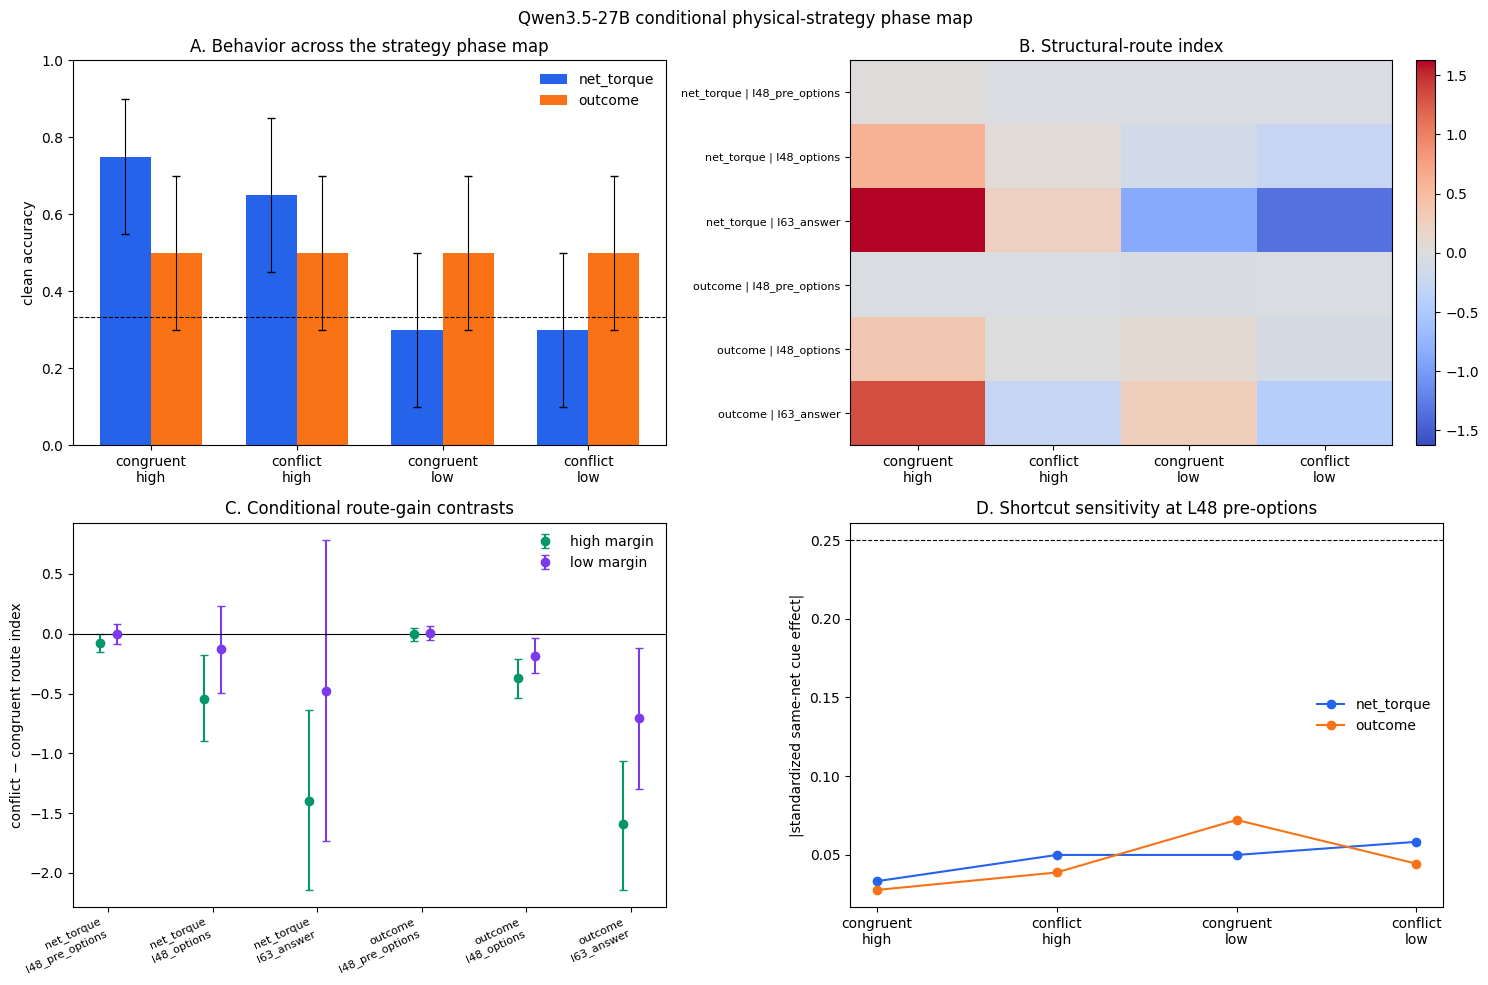

Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_conditional_strategy_phase_map_v1/models/Qwen__Qwen3.5-27B__373612cb/analysis/figures/qwen27b_conditional_strategy_phase_map.png


In [16]:
%%cell_progress 15/17 Save the paper-facing strategy phase map
cell_stage('Rendering behavior, route index, conflict gains, and cue leakage')

site_order = [site[2] for site in DIRECT_SITES]
cell_order = [
    ('congruent', 'high'), ('conflict', 'high'),
    ('congruent', 'low'), ('conflict', 'low'),
]
cell_labels = ['congruent\nhigh', 'conflict\nhigh', 'congruent\nlow', 'conflict\nlow']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

ax = axes[0, 0]
x = np.arange(len(cell_order))
width = .35
for task_index, (task, color) in enumerate((
    ('net_torque', '#2563eb'), ('outcome', '#f97316')
)):
    values = []
    errors_low = []
    errors_high = []
    for cue_class, margin_bin in cell_order:
        row = behavior_cells[
            (behavior_cells['task'] == task)
            & (behavior_cells['cue_class'] == cue_class)
            & (behavior_cells['margin_bin'] == margin_bin)
        ].iloc[0]
        values.append(float(row['mean']))
        errors_low.append(float(row['mean'] - row['ci_low']))
        errors_high.append(float(row['ci_high'] - row['mean']))
    position = x + (task_index - .5) * width
    ax.bar(position, values, width=width, color=color, label=task)
    ax.errorbar(
        position, values, yerr=np.vstack([errors_low, errors_high]),
        fmt='none', color='black', capsize=3, linewidth=.8,
    )
ax.axhline(1/3, color='black', linestyle='--', linewidth=.8)
ax.set_xticks(x, cell_labels)
ax.set_ylim(0, 1)
ax.set_ylabel('clean accuracy')
ax.set_title('A. Behavior across the strategy phase map')
ax.legend(frameon=False)

ax = axes[0, 1]
heat = []
heat_labels = []
for task in PRIMARY_TASKS:
    for site in site_order:
        row_values = []
        for cue_class, margin_bin in cell_order:
            row = cell_tests[
                (cell_tests['task'] == task)
                & (cell_tests['site_label'] == site)
                & (cell_tests['cue_class'] == cue_class)
                & (cell_tests['margin_bin'] == margin_bin)
                & (cell_tests['metric'] == 'route_index')
            ].iloc[0]
            row_values.append(float(row['mean']))
        heat.append(row_values)
        heat_labels.append(f'{task} | {site}')
heat = np.asarray(heat, dtype=float)
limit = max(.25, float(np.nanmax(np.abs(heat))))
image = ax.imshow(heat, aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
ax.set_xticks(np.arange(len(cell_labels)), cell_labels)
ax.set_yticks(np.arange(len(heat_labels)), heat_labels, fontsize=8)
ax.set_title('B. Structural-route index')
fig.colorbar(image, ax=ax, fraction=.046, pad=.04)

ax = axes[1, 0]
positions = np.arange(len(PRIMARY_TASKS) * len(site_order))
labels = [f'{task}\n{site}' for task in PRIMARY_TASKS for site in site_order]
for offset, margin_bin, color in (
    (-.08, 'high', '#059669'), (.08, 'low', '#7c3aed')
):
    rows = []
    for task in PRIMARY_TASKS:
        for site in site_order:
            rows.append(contrast_tests[
                (contrast_tests['task'] == task)
                & (contrast_tests['site_label'] == site)
                & (contrast_tests['metric'] == 'route_index')
                & (contrast_tests['margin_bin'] == margin_bin)
            ].iloc[0])
    means = np.asarray([row['estimate'] for row in rows], dtype=float)
    lows = np.asarray([row['ci_low'] for row in rows], dtype=float)
    highs = np.asarray([row['ci_high'] for row in rows], dtype=float)
    ax.errorbar(
        positions + offset, means,
        yerr=np.vstack([means - lows, highs - means]),
        marker='o', linestyle='none', capsize=3,
        color=color, label=f'{margin_bin} margin',
    )
ax.axhline(0, color='black', linewidth=.8)
ax.set_xticks(positions, labels, rotation=25, ha='right', fontsize=8)
ax.set_ylabel('conflict − congruent route index')
ax.set_title('C. Conditional route-gain contrasts')
ax.legend(frameon=False)

ax = axes[1, 1]
for index, (task, color) in enumerate((
    ('net_torque', '#2563eb'), ('outcome', '#f97316')
)):
    rows = []
    for cue_class, margin_bin in cell_order:
        row = cell_tests[
            (cell_tests['task'] == task)
            & (cell_tests['site_label'] == 'l48_pre_options')
            & (cell_tests['cue_class'] == cue_class)
            & (cell_tests['margin_bin'] == margin_bin)
            & (cell_tests['metric'] == 'std_cue_base_margin_change')
        ].iloc[0]
        rows.append(row)
    means = np.asarray([row['mean'] for row in rows], dtype=float)
    ax.plot(x, means, marker='o', color=color, label=task)
ax.axhline(EQUIVALENCE_FRACTION, color='black', linestyle='--', linewidth=.8)
ax.set_xticks(x, cell_labels)
ax.set_ylabel('|standardized same-net cue effect|')
ax.set_title('D. Shortcut sensitivity at L48 pre-options')
ax.legend(frameon=False)

fig.suptitle('Qwen3.5-27B conditional physical-strategy phase map')
fig.tight_layout()
figure_path = FIGURE_DIR / 'qwen27b_conditional_strategy_phase_map.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [17]:
%%cell_progress 16/17 Apply the frozen strategy decision tree
cell_stage('Combining competence, route interaction, invariance, and robustness')

high_competence_rows = behavior_cells[
    behavior_cells['task'].isin(PRIMARY_TASKS)
    & (behavior_cells['margin_bin'] == 'high')
]
assert len(high_competence_rows) == 4
high_margin_competence_gate = bool(
    (high_competence_rows['mean'] >= MIN_HIGH_MARGIN_ACCURACY).all()
)

primary_rows = contrast_tests[
    (contrast_tests['metric'] == 'route_index')
    & (contrast_tests['margin_bin'] == 'high')
    & (contrast_tests['contrast'] == 'conflict_minus_congruent')
].copy()
primary_rows['positive_fdr'] = (
    (primary_rows['ci_low'] > 0)
    & (primary_rows['q_value'] < ALPHA)
)
primary_with_robustness = primary_rows.merge(
    robustness_frame, on=['task', 'site_label'], validate='one_to_one'
)
primary_with_robustness['robust_positive'] = (
    primary_with_robustness['positive_fdr']
    & (primary_with_robustness['loo_min_high_route_gain'] > 0)
    & (primary_with_robustness['matched_high_route_gain'] > 0)
    & primary_with_robustness['both_conflict_types_positive']
)
adaptive_signal = bool(primary_with_robustness['robust_positive'].any())

def cell_test_row(task, site_label, cue_class, margin_bin, metric):
    rows = cell_tests[
        (cell_tests['task'] == task)
        & (cell_tests['site_label'] == site_label)
        & (cell_tests['cue_class'] == cue_class)
        & (cell_tests['margin_bin'] == margin_bin)
        & (cell_tests['metric'] == metric)
    ]
    assert len(rows) == 1
    return rows.iloc[0]

structural_sites = []
for task in PRIMARY_TASKS:
    for site_label in [site[2] for site in DIRECT_SITES]:
        mirror_positive = []
        cue_equivalent = []
        for cue_class, margin_bin in (
            ('congruent', 'high'), ('conflict', 'high'),
            ('congruent', 'low'), ('conflict', 'low'),
        ):
            mirror = cell_test_row(
                task, site_label, cue_class, margin_bin,
                'std_mirror_target_shift',
            )
            cue = cell_test_row(
                task, site_label, cue_class, margin_bin,
                'std_cue_base_margin_change',
            )
            mirror_positive.append(bool(mirror['ci_low'] > 0))
            cue_equivalent.append(bool(cue['ci_high'] < EQUIVALENCE_FRACTION))
        if all(mirror_positive) and all(cue_equivalent):
            structural_sites.append({'task': task, 'site_label': site_label})
condition_invariant_structural_route = bool(structural_sites)

high_behavior_drop = behavior_contrasts[
    behavior_contrasts['margin_bin'] == 'high'
]
behavioral_conflict_cost = bool((high_behavior_drop['ci_low'] > 0).any())
causal_cue_sensitivity = bool(
    len(matched_cue_tests)
    and (matched_cue_tests['ci_low'] > EQUIVALENCE_FRACTION).any()
)
shortcut_sensitive = bool(behavioral_conflict_cost or causal_cue_sensitivity)

if adaptive_signal and high_margin_competence_gate:
    decision = 'cue_conflict_adaptive_route_switch_supported'
elif adaptive_signal:
    decision = 'route_interaction_detected_but_competence_gate_failed'
elif condition_invariant_structural_route and high_margin_competence_gate:
    decision = 'condition_invariant_torque_equivalent_route_supported'
elif shortcut_sensitive:
    decision = 'shortcut_sensitive_without_adaptive_route_switch'
elif not high_margin_competence_gate:
    decision = 'strategy_claim_blocked_by_high_margin_competence'
else:
    decision = 'conditional_strategy_selection_not_supported'

decision_payload = {
    'schema_version': 'qwen27b-conditional-strategy-decision-1.0',
    'decision': decision,
    'model_id': MODEL_ID, 'model_revision': MODEL_REVISION,
    'families': EXPECTED_FAMILIES,
    'unique_scenes': 3 * EXPECTED_FAMILIES,
    'manifest_sha256': manifest_sha256,
    'claim_registry_sha256': protocol_sha256,
    'high_margin_competence_gate': high_margin_competence_gate,
    'adaptive_signal': adaptive_signal,
    'condition_invariant_structural_route': (
        condition_invariant_structural_route
    ),
    'shortcut_sensitive': shortcut_sensitive,
    'behavioral_conflict_cost': behavioral_conflict_cost,
    'causal_cue_sensitivity': causal_cue_sensitivity,
    'passing_adaptive_rows': primary_with_robustness.loc[
        primary_with_robustness['robust_positive'],
        ['task', 'site_label', 'estimate', 'ci_low', 'ci_high', 'q_value']
    ].to_dict(orient='records'),
    'structural_sites': structural_sites,
    'primary_tests': primary_with_robustness.to_dict(orient='records'),
    'high_margin_competence': high_competence_rows.to_dict(orient='records'),
    'limitations': [
        'The phase map uses clean synthetic single-stack scenes with an explicit rule.',
        'Cue donors preserve signed net torque but may differ modestly in normalized margin; the matched subset is reported separately.',
        'Grouped residual-stream interchange does not identify a unique circuit.',
        'Correctness is never used for support selection or the primary route estimand.',
        'A null at the three frozen sites does not exclude a distributed strategy change.',
    ],
}
DECISION_PATH = ANALYSIS_DIR / 'conditional_strategy_decision.json'
write_json_atomic(DECISION_PATH, decision_payload)
print(json.dumps(decision_payload, indent=2))


Apply the frozen strategy decision tree:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{
  "schema_version": "qwen27b-conditional-strategy-decision-1.0",
  "decision": "shortcut_sensitive_without_adaptive_route_switch",
  "model_id": "Qwen/Qwen3.5-27B",
  "model_revision": "373612cb4f9288fcf550b526d86d85febedd9801",
  "families": 80,
  "unique_scenes": 240,
  "manifest_sha256": "sha256:fddc71888955426c729666a37ee1b54da3adaa0121ce947b034ac4c52117e476",
  "claim_registry_sha256": "sha256:41ecc7fc9273f68423221859c26816cb298bc90546f1e31b1df56e1274cf471d",
  "high_margin_competence_gate": true,
  "adaptive_signal": false,
  "condition_invariant_structural_route": false,
  "shortcut_sensitive": true,
  "behavioral_conflict_cost": false,
  "causal_cue_sensitivity": true,
  "passing_adaptive_rows": [],
  "structural_sites": [],
  "primary_tests": [
    {
      "task": "net_torque",
      "site_label": "l48_pre_options",
      "margin_bin": "high",
      "metric": "route_index",
      "contrast": "conflict_minus_congruent",
      "left_n": 20,
      "right_n": 20,
      "estimate

In [18]:
%%cell_progress 17/17 Export the claim card and readable report
cell_stage('Writing the decision-aware strategy report')

interpretations = {
    'cue_conflict_adaptive_route_switch_supported': (
        'At a frozen site, high-margin cue conflict increases physical-route '
        'transport relative to same-net cue sensitivity, with competence, '
        'multiplicity, donor matching, conflict-type, and LOO gates satisfied.'
    ),
    'route_interaction_detected_but_competence_gate_failed': (
        'A conditional route interaction is present, but high-margin clean '
        'performance is too weak for a strong adaptive-strategy claim.'
    ),
    'condition_invariant_torque_equivalent_route_supported': (
        'The same structural route operates across conditions: mirror changes '
        'are transported while same-net cue changes remain equivalent to zero, '
        'without evidence that cue conflict strengthens the route.'
    ),
    'shortcut_sensitive_without_adaptive_route_switch': (
        'Behavior or causal readout remains sensitive to cue congruence, but '
        'the model does not show the preregistered conflict-triggered increase '
        'in the structural route.'
    ),
    'strategy_claim_blocked_by_high_margin_competence': (
        'Even the high-margin cells are below the frozen competence gate, so '
        'route differences cannot support a strategy-selection claim.'
    ),
    'conditional_strategy_selection_not_supported': (
        'The frozen sites do not show a reliable conflict-triggered route '
        'change or a condition-invariant structural route on competent support.'
    ),
}

report_lines = [
    '# Qwen-27B conditional strategy phase map', '',
    f"- Decision: `{decision_payload['decision']}`",
    f'- Families: {EXPECTED_FAMILIES}',
    f'- Unique scenes: {3 * EXPECTED_FAMILIES}',
    f'- High-margin competence gate: {high_margin_competence_gate}',
    f'- Adaptive route signal: {adaptive_signal}',
    f'- Condition-invariant structural route: {condition_invariant_structural_route}',
    f'- Shortcut sensitivity: {shortcut_sensitive}', '',
    '## Interpretation', '', interpretations[decision_payload['decision']], '',
    '## Evidence boundary', '',
    'The primary claim is an interaction: conflict versus congruent route '
    'index at high physical margin. Separate within-cell significance is not '
    'used as evidence for switching. Low-margin and difference-in-differences '
    'results diagnose uncertainty but do not replace the high-margin test. '
    'Correctness is reported without conditioning the mechanism analysis.', '',
    '## Recommended next step', '',
]
if adaptive_signal and high_margin_competence_gate:
    report_lines.extend([
        'Freeze the passing task/site and test direct answering versus a '
        'structured calculate-first prompt on new conflict scenes. The next '
        'claim is whether added reasoning changes the causal route rather than '
        'only the generated explanation.', '',
    ])
elif condition_invariant_structural_route:
    report_lines.extend([
        'Treat the fast route as a candidate distributed torque-equivalent '
        'computation and replicate its same-net invariance on multi-stack '
        'decompositions before adding adaptive routing.', '',
    ])
elif shortcut_sensitive:
    report_lines.extend([
        'Use the frozen conflict support for a direct-versus-structured '
        'calculation experiment. Test whether explicit calculation suppresses '
        'cue sensitivity and increases structural transport.', '',
    ])
else:
    report_lines.extend([
        'Do not add model training or compute routing yet. Treat strategy '
        'selection as unresolved and retain the result as a boundary on the '
        'three frozen residual-stream sites.', '',
    ])

REPORT_PATH = ANALYSIS_DIR / 'conditional_strategy_report.md'
REPORT_PATH.write_text('\n'.join(report_lines) + '\n', encoding='utf-8')
write_json_atomic(ANALYSIS_DIR / 'paper_claim_card.json', {
    'decision': decision_payload['decision'],
    'interpretation': interpretations[decision_payload['decision']],
    'adaptive_signal': adaptive_signal,
    'condition_invariant_structural_route': condition_invariant_structural_route,
    'shortcut_sensitive': shortcut_sensitive,
    'passing_adaptive_rows': decision_payload['passing_adaptive_rows'],
    'nonclaim': (
        'This experiment does not identify a unique circuit or establish '
        'human-like System 1/System 2 processing.'
    ),
})
print(REPORT_PATH.read_text(encoding='utf-8'))
print('All outputs:', ANALYSIS_DIR)


Export the claim card and readable report:  94%|#########4| 16/17 [00:00<?, ?cell/s]

# Qwen-27B conditional strategy phase map

- Decision: `shortcut_sensitive_without_adaptive_route_switch`
- Families: 80
- Unique scenes: 240
- High-margin competence gate: True
- Adaptive route signal: False
- Condition-invariant structural route: False
- Shortcut sensitivity: True

## Interpretation

Behavior or causal readout remains sensitive to cue congruence, but the model does not show the preregistered conflict-triggered increase in the structural route.

## Evidence boundary

The primary claim is an interaction: conflict versus congruent route index at high physical margin. Separate within-cell significance is not used as evidence for switching. Low-margin and difference-in-differences results diagnose uncertainty but do not replace the high-margin test. Correctness is reported without conditioning the mechanism analysis.

## Recommended next step

Use the frozen conflict support for a direct-versus-structured calculation experiment. Test whether explicit calculation suppresse